# Background

- **Author**: 待學生填寫（已詢問）
- **Created At**: 2026-11-08
- **Research Motivation and Context (why are we interested in the findings?)：** 沿用既有 MA／MS 分析，比較夏威夷（HI）與佛蒙特州（VT）各州收入四分位組內白人、亞洲人與黑人的房貸核准率。使用指定的 [state_HI-VT_white_percentage_15_columns.csv](../data/processed/state_HI-VT_white_percentage_15_columns.csv) 與 [資料驗證文件](../data/processed/state_HI-VT_income_documentation.ipynb)。收入門檻讀取 [income_quartiles_2024.csv](../data/processed/income_quartiles_2024.csv)，產生程式為 [calculate_income_quartiles_by_race.py](../data/code/calculate_income_quartiles_by_race.py)；使用州整體家戶門檻，同州各種族共用界線。
- **Main Findings and Takeaways：** 來源檔 39,292 筆；收入缺失 2,323 筆；三種族有效收入分析樣本 25,267 筆。門檻（美元）為 HI 52,691.475／100,103.65／172,592.5，VT 45,990.825／85,281／142,135。VT 白人在 Q1–Q4 的核准率皆高於 HI（51.4%／76.7%／84.9%／88.3%，對照 47.5%／65.2%／72.8%／78.7%）。VT 亞洲人 Q1 為 18.2%（n=11），黑人 Q1 為 11.1%（n=9），小樣本區間較寬。各組為描述性比較，不代表因果效果。執行狀態：乾淨 Jupyter kernel 完整執行，24 組結果與輸出 CSV 重新讀取核對通過；4 張分組圖及總覽圖已核對。
- **Future Direction：** 本次為描述性比較，未控制貸款條件、信用狀況或機構差異；後續如需解釋差距，須另確認研究設計。


In [1]:
# Load packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib import font_manager
from IPython.display import Markdown
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Heiti TC', 'Arial Unicode VT', 'Noto Sans CJK TC'] if f in available_fonts), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 11


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p / 'AGENTS.md').is_file() and (p / 'templates').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('請從 econ-5166-student-kit 或其子目錄執行。')
INPUT_PATH = 'data/processed/state_HI-VT_white_percentage_15_columns.csv'
EXPECTED_SHA256 = '962fb1339dbc92effc07c0d793089307d05f22fc78e01d6daf63741ffd7d9da6'
input_file = (PROJECT_ROOT / INPUT_PATH).resolve()
assert input_file.is_relative_to((PROJECT_ROOT / 'data/processed').resolve())
if hashlib.sha256(input_file.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError('資料版本已改變，請先核對資料來源。')
df = pd.read_csv(input_file)

# 僅做簡單篩選與少量變數產生，不覆寫輸入。
assert df.shape == (39292, 15)
assert {'state_code','derived_race','income','action_taken'} <= set(df.columns)
assert set(df.state_code) == {'HI','VT'}
assert set(df.action_taken) == {1,2,3}
display(df.head(10))

# Bind the separately verified ACS household-income thresholds (USD).
QUARTILE_INPUT_PATH = 'data/processed/income_quartiles_2024.csv'
QUARTILE_SHA256 = '3b47360827eb8bf7fc0997a3f7fe4712093e64620ee48cfdc04ccbba22375c96'
quartile_file = (PROJECT_ROOT / QUARTILE_INPUT_PATH).resolve()
assert quartile_file.is_relative_to((PROJECT_ROOT / 'data/processed').resolve())
if hashlib.sha256(quartile_file.read_bytes()).hexdigest() != QUARTILE_SHA256:
    raise ValueError('ACS 收入門檻檔案版本已變更，請先核對。')
quartile_source = pd.read_csv(quartile_file)
assert len(quartile_source)==4 and quartile_source.state.is_unique
assert set(quartile_source.state)=={'MA','MS','HI','VT'}
quartile_source = quartile_source.loc[quartile_source.state.isin(['HI','VT'])].copy()
assert set(quartile_source.state)=={'HI','VT'}
assert {'state','Q1','Median','Q3'} <= set(quartile_source.columns)
assert (quartile_source.Q1 < quartile_source.Median).all()
assert (quartile_source.Median < quartile_source.Q3).all()
print('收入門檻原始資料（美元）：')
display(quartile_source)


,state_code,county_code,derived_ethnicity,derived_race,derived_sex,action_taken,loan_type,loan_purpose,loan_amount,loan_to_value_ratio,property_value,occupancy_type,income,debt_to_income_ratio,applicant_age
0,HI,15009.0,Ethnicity Not Available,Race Not Available,Joint,3,1,1,795000.0,80.00000,995000,1,175.0,38,35-44
1,HI,15003.0,Not Hispanic or Latino,White,Female,1,3,1,515000.0,99.99800,515000,1,250.0,<20%,25-34
2,HI,15003.0,Hispanic or Latino,Asian,Male,1,3,1,555000.0,90.00400,625000,1,113.0,30%-<36%,25-34
3,HI,15001.0,Joint,Joint,Joint,1,3,1,725000.0,99.31700,735000,1,190.0,36,45-54
4,HI,15003.0,Hispanic or Latino,Race Not Available,Male,1,3,1,545000.0,100.00000,545000,1,145.0,45,25-34
5,VT,50011.0,Not Hispanic or Latino,White,Male,1,3,32,325000.0,90.00000,365000,1,86.0,49,55-64
6,VT,50021.0,Hispanic or Latino,Race Not Available,Male,1,3,31,255000.0,NaN,NaN,1,NaN,NaN,35-44
7,VT,50017.0,Not Hispanic or Latino,White,Joint,1,2,32,285000.0,80.00000,345000,1,158.0,42,45-54
8,HI,15003.0,Not Hispanic or Latino,Asian,Male,1,3,1,815000.0,100.00000,815000,1,161.0,>60%,35-44
9,HI,15003.0,Ethnicity Not Available,Race Not Available,Male,1,3,1,865000.0,97.19100,895000,1,180.0,46,35-44


收入門檻原始資料（美元）：


,state,state_fips,sample_size_before_cleaning,sample_size_after_cleaning,estimated_households,Q1,Median,Q3,IQR
2,HI,15,6498,5181,493151,52691.475,100103.65,172592.5,119901.025
3,VT,50,3875,2959,285548,45990.825,85281.00,142135.0,96144.175


## 樣本與定義

- 核准：`action_taken ∈ {1,2}`；拒絕：`action_taken = 3`。核准率 = 核准筆數 /（核准＋拒絕筆數）。核准不等同於實際撥款。
- 四分位門檻：依使用者指定，直接使用 `income_quartiles_2024.csv` 中各州的 Q1、Median、Q3（2024 ACS 加權家戶年收入四分位數，單位為美元）。這些界線對同州所有種族相同；不從房貸資料重新估計門檻，也不按種族重算。
- 單位換算：房貸 `income` 為千美元，ACS 門檻為美元，因此將 ACS 門檻除以 1,000 後與房貸收入比較；例如 HI 的 P25 為 52,691.475 美元，等於 52.691475 千美元。
- Q1：收入 ≤ P25；Q2：P25 < 收入 ≤ P50；Q3：P50 < 收入 ≤ P75；Q4：收入 > P75。同收入者留在同一組，因此房貸申請的各組筆數不必占 25%；四分位數描述的是 ACS 家戶收入分布。
- 收入缺失／非有限值無法分組，排除並列出筆數；保留有效的零與負收入，不任意刪除極端值。無申請識別碼，故不依 15 欄完全相同就去重。
- 繪圖只保留 `derived_race` 的 White、Asian、Black or African American。這是檔案提供的彙整種族分類；不額外限制族裔、貸款類型、用途或自住條件，不加權。
- 收入單位依 [HMDA 官方欄位定義](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields/)為千美元。原檔下載來源與年份未提供，欄位對照不代表已驗證來源或年份。


In [3]:
# Summary statistics before analysis: every variable actually used
print(f'表 1：來源檔收入摘要（總 N={len(df):,}；N 為有效數值筆數）')
income_numeric = pd.to_numeric(df['income'], errors='coerce')
finite = income_numeric.notna() & np.isfinite(income_numeric)
display(income_numeric[finite].describe().rename(index={'count':'N','mean':'平均','std':'標準差','min':'最小值','25%':'第25百分位','50%':'中位數','75%':'第75百分位','max':'最大值'}).to_frame('年收入（千美元）'))
print('收入缺失／非有限值：', int((~finite).sum()))
for col, label in [('state_code','州別'),('derived_race','種族'),('action_taken','申請結果')]:
    counts = df[col].value_counts(dropna=True)
    print(f'表 2：{label}（有效 N={counts.sum():,}；缺失 N={df[col].isna().sum():,}）')
    display(pd.DataFrame({'筆數':counts, '比例 (%)':counts / counts.sum() * 100}))

print('門檻來源資料摘要（各州一列，共 N=2；年收入門檻單位為美元）')
display(quartile_source[['Q1','Median','Q3']].describe().T)
print('州別：HI 與 VT 各 1 列、各占 50%；必要門檻欄位缺失數：')
display(quartile_source[['state','Q1','Median','Q3']].isna().sum().to_frame('缺失數'))


表 1：來源檔收入摘要（總 N=39,292；N 為有效數值筆數）


,年收入（千美元）
N,36969.000000
平均,197.481944
標準差,466.085362
最小值,-4695.000000
第25百分位,84.000000
中位數,130.000000
第75百分位,200.000000
最大值,29850.000000


收入缺失／非有限值： 2323
表 2：州別（有效 N=39,292；缺失 N=0）


,筆數,比例 (%)
state_code,,
HI,24196,61.579965
VT,15096,38.420035


表 2：種族（有效 N=39,292；缺失 N=0）


,筆數,比例 (%)
derived_race,,
White,17682,45.001527
Asian,8085,20.576708
Race Not Available,7407,18.851166
Joint,2441,6.212461
Native Hawaiian or Other Pacific Islander,1803,4.588720
2 or more minority races,1161,2.954800
Black or African American,517,1.315789
American Indian or Alaska Native,194,0.493739
Free Form Text Only,2,0.005090


... (2 outputs left out)

門檻來源資料摘要（各州一列，共 N=2；年收入門檻單位為美元）


,count,mean,std,min,25%,50%,75%,max
Q1,2.0,49341.150,4738.075053,45990.825,47665.9875,49341.150,51016.3125,52691.475
Median,2.0,92692.325,10481.196330,85281.000,88986.6625,92692.325,96397.9875,100103.650
Q3,2.0,157363.750,21536.704788,142135.000,149749.3750,157363.750,164978.1250,172592.500


州別：HI 與 VT 各 1 列、各占 50%；必要門檻欄位缺失數：


,缺失數
state,0
Q1,0
Median,0
Q3,0


### The actual analysis starts below

In [4]:
eligible = df.loc[df.action_taken.isin([1,2,3]) & finite].copy()
eligible['income'] = income_numeric.loc[eligible.index]
eligible['approved'] = eligible.action_taken.isin([1,2]).astype(int)
cutoffs = quartile_source.set_index('state')[['Q1','Median','Q3']].rename(columns={'Q1':'P25','Median':'P50','Q3':'P75'}).reindex(['HI','VT']) / 1000
cutoffs.index.name = 'state_code'
assert (cutoffs.P25 < cutoffs.P50).all() and (cutoffs.P50 < cutoffs.P75).all()
eligible['income_quartile'] = pd.Series(index=eligible.index, dtype='string')
for state in ['HI','VT']:
    mask = eligible.state_code.eq(state)
    boundaries = [-np.inf, *cutoffs.loc[state].tolist(), np.inf]
    eligible.loc[mask,'income_quartile'] = pd.cut(eligible.loc[mask,'income'], boundaries, labels=['Q1','Q2','Q3','Q4'], right=True).astype('string')
assert eligible.income_quartile.notna().all()
print('表 3：各州 ACS 家戶收入門檻（已換算為千美元）；申請紀錄數僅描述本次收入有效的貸款樣本，不用於計算門檻')
display(cutoffs.join(eligible.groupby('state_code').size().rename('有效收入申請數')))
races = ['White','Asian','Black or African American']
analysis = eligible.loc[eligible.derived_race.isin(races)].copy()
print(f'表 4：三種族繪圖樣本 N={len(analysis):,}；排除其他種族 {len(eligible)-len(analysis):,} 筆')
display(pd.crosstab(analysis.state_code,analysis.income_quartile))
print('表 5：衍生變數摘要（分母為繪圖樣本非缺失數）')
for col in ['approved','income_quartile']:
    counts = analysis[col].value_counts(dropna=True).sort_index()
    display(pd.DataFrame({'筆數':counts,'比例 (%)':counts / counts.sum()*100}))
display(analysis[['income','approved']].describe().T)


表 3：各州 ACS 家戶收入門檻（已換算為千美元）；申請紀錄數僅描述本次收入有效的貸款樣本，不用於計算門檻


,P25,P50,P75,有效收入申請數
state_code,,,,
HI,52.691475,100.10365,172.5925,22566
VT,45.990825,85.28100,142.1350,14403


表 4：三種族繪圖樣本 N=25,267；排除其他種族 11,702 筆


income_quartile,Q1,Q2,Q3,Q4
state_code,,,,
HI,1107,2785,4417,5136
VT,1022,3105,3655,4040


表 5：衍生變數摘要（分母為繪圖樣本非缺失數）


,筆數,比例 (%)
approved,,
0,6254,24.751652
1,19013,75.248348


,筆數,比例 (%)
income_quartile,,
Q1,2129,8.42601
Q2,5890,23.311038
Q3,8072,31.946808
Q4,9176,36.316144


,count,mean,std,min,25%,50%,75%,max
income,25267.0,194.282068,447.360395,-4695.0,81.0,126.0,197.0,23521.0
approved,25267.0,0.752483,0.431578,0.0,1.0,1.0,1.0,1.0


In [5]:
# Wilson 95% intervals: descriptive binomial intervals, no lender clustering
idx = pd.MultiIndex.from_product([['Q1','Q2','Q3','Q4'],['HI','VT'],races],names=['income_quartile','state_code','derived_race'])
summary = analysis.groupby(['income_quartile','state_code','derived_race']).agg(approved_n=('approved','sum'),n=('approved','size')).reindex(idx)
summary[['approved_n','n']] = summary[['approved_n','n']].fillna(0).astype(int)
summary['denied_n'] = summary.n-summary.approved_n
summary['approval_rate'] = summary.approved_n / summary.n.replace(0,np.nan)
z=1.959963984540054
n=summary.n.replace(0,np.nan)
p=summary.approval_rate
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
summary['ci95_low']=(center-half).clip(0,1)
summary['ci95_high']=(center+half).clip(0,1)
assert summary.n.sum()==len(analysis)
assert summary.approved_n.sum()==analysis.approved.sum()
valid = summary.n.gt(0)
assert summary.loc[valid,'approval_rate'].between(0,1).all()
assert (summary.loc[valid,'ci95_low'] <= summary.loc[valid,'approval_rate']+1e-12).all()
assert (summary.loc[valid,'ci95_high'] >= summary.loc[valid,'approval_rate']-1e-12).all()
print(f'表 6：各收入組、州、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N={len(analysis):,}）')
display(summary)
assets=PROJECT_ROOT/'finding/assets/hi_vt_mortgage_approval'
assets.mkdir(parents=True,exist_ok=True)
summary.to_csv(assets/'approval_rates.csv')
cutoffs.to_csv(assets/'income_quartile_thresholds.csv')
# Reopen serialized result tables and verify their counts and values.
saved=pd.read_csv(assets/'approval_rates.csv')
assert len(saved)==24 and saved.n.sum()==len(analysis)
assert np.allclose(saved.approval_rate, summary.approval_rate, equal_nan=True)
assert np.allclose(pd.read_csv(assets/'income_quartile_thresholds.csv',index_col=0),cutoffs)


表 6：各收入組、州、種族的核准筆數、總筆數、核准率與 95% 信賴區間（總 N=25,267）


approved_n     n  \
income_quartile state_code derived_race                                  
Q1              HI         White                             256   539   
                           Asian                             219   559   
                           Black or African American           6     9   
                VT         White                             515  1002   
                           Asian                               2    11   
                           Black or African American           1     9   
Q2              HI         White                             617   946   
                           Asian                            1033  1761   
                           Black or African American          52    78   
                VT         White                            2306  3005   
                           Asian                              50    67   
                           Black or African American          15    33   
Q3              HI         White                            1146  1575   
                           Asian                            1974  2700   
                           Black or African American          91   142   
                VT         White                            3023  3560   
                           Asian                              50    65   
                           Black or African American          21    30   
Q4              HI         White                            1932  2456   
                           Asian                            2053  2555   
                           Black or African American          85   125   
                VT         White                            3482  3943   
                           Asian                              69    80   
                           Black or African American          15    17   

                                                      denied_n  approval_rate  \
income_quartile state_code derived_race                                         
Q1              HI         White                           283       0.474954   
                           Asian                           340       0.391771   
                           Black or African American         3       0.666667   
                VT         White                           487       0.513972   
                           Asian                             9       0.181818   
                           Black or African American         8       0.111111   
Q2              HI         White                           329       0.652220   
                           Asian                           728       0.586599   
                           Black or African American        26       0.666667   
                VT         White                           699       0.767388   
                           Asian                            17       0.746269   
                           Black or African American        18       0.454545   
Q3              HI         White                           429       0.727619   
                           Asian                           726       0.731111   
                           Black or African American        51       0.640845   
                VT         White                           537       0.849157   
                           Asian                            15       0.769231   
                           Black or African American         9       0.700000   
Q4              HI         White                           524       0.786645   
                           Asian                           502       0.803523   
                           Black or African American        40       0.680000   
                VT         White                           461       0.883084   
                           Asian                            11       0.862500   
                           Black or African American         2       0.882353   

                      

## 四張收入組比較圖

長條為核准率，誤差線為 Wilson 95% 信賴區間，`n` 為該州／種族／收入組的核准加拒絕筆數。區間以申請紀錄互相獨立的二項模型計算，未調整同一貸款機構或重複申請的相關性；這些區間用於描述，不能視為已控制混淆因素的差距檢定。

各州的實際收入界線列於橫軸；相同 Q 組表示相對於各州 2024 ACS 家戶收入分布的位置，並不表示兩州收入金額相同。四張圖顏色與縱軸一致。


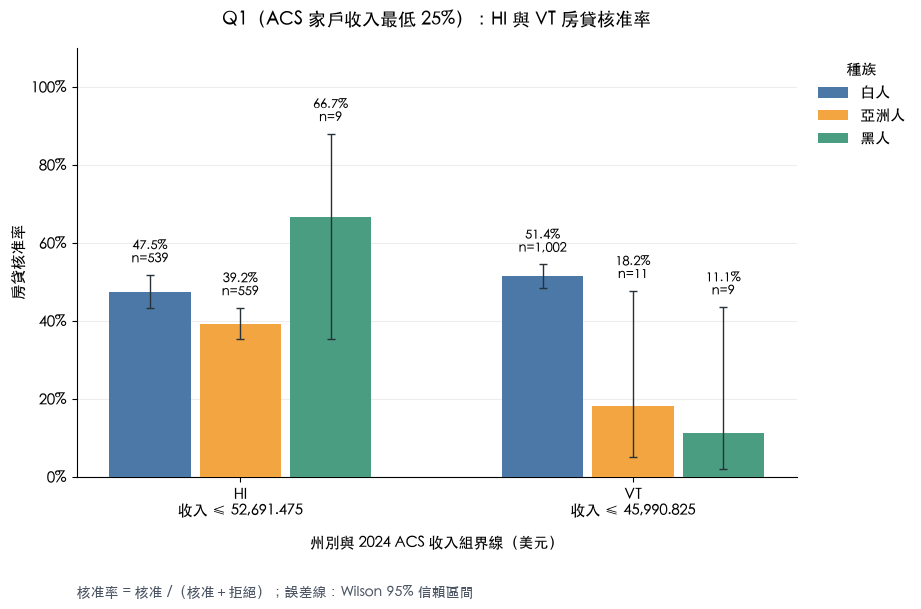

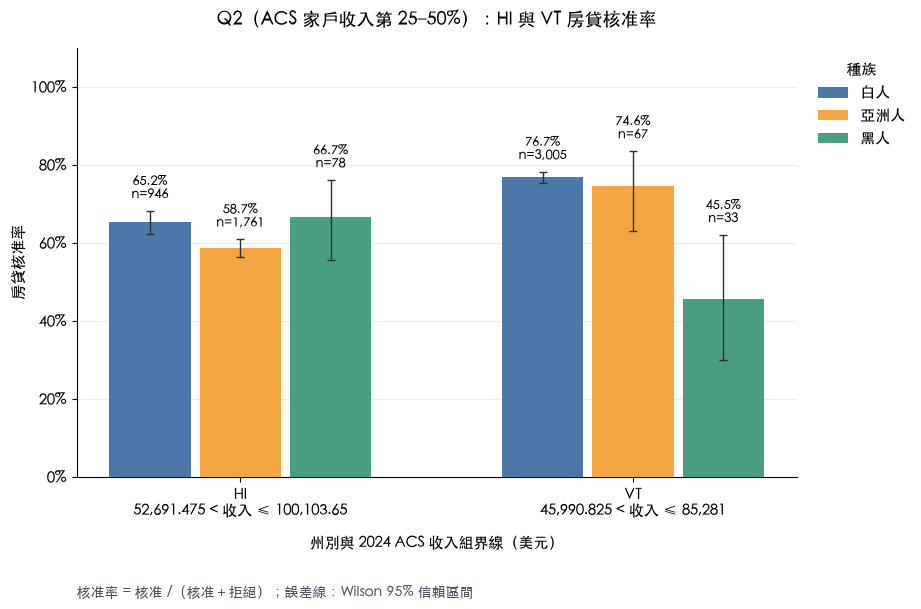

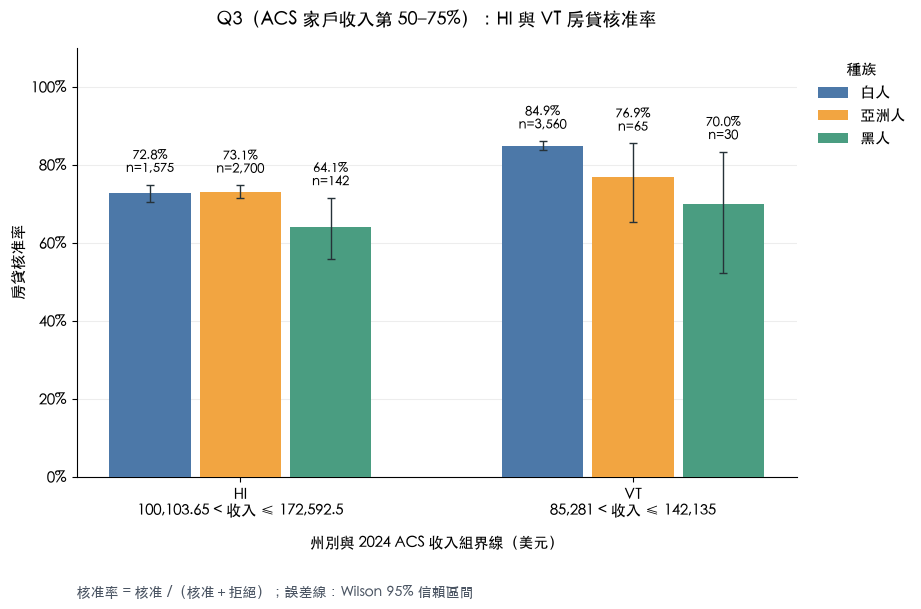

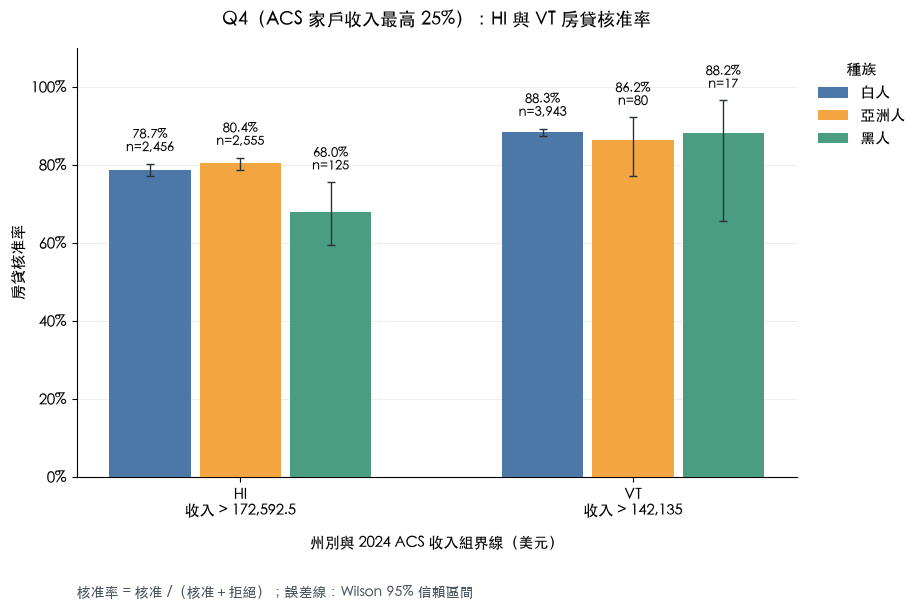

In [6]:
colors=['#4C78A8','#F2A541','#4A9D81']
race_labels=['白人','亞洲人','黑人']
quartile_labels={'Q1':'ACS 家戶收入最低 25%','Q2':'ACS 家戶收入第 25–50%','Q3':'ACS 家戶收入第 50–75%','Q4':'ACS 家戶收入最高 25%'}
def income_range(state,q):
    a,b,c=[f'{v*1000:,.3f}'.rstrip('0').rstrip('.') for v in cutoffs.loc[state]]
    return {'Q1':f'收入 ≤ {a}', 'Q2':f'{a} < 收入 ≤ {b}', 'Q3':f'{b} < 收入 ≤ {c}', 'Q4':f'收入 > {c}'}[q]
def draw_chart(ax,q):
    width=.23
    for j,(race,label,color) in enumerate(zip(races,race_labels,colors)):
        group=summary.xs((q,race),level=('income_quartile','derived_race')).reindex(['HI','VT'])
        x=np.arange(2)+(j-1)*width
        for k,row in enumerate(group.itertuples()):
            if row.n==0:
                ax.text(x[k],.025,'無樣本',ha='center',fontsize=9)
                continue
            ax.bar(x[k],row.approval_rate,width*.9,color=color,label=label if k==0 else None,zorder=3)
            ax.errorbar(x[k],row.approval_rate,yerr=[[max(0,row.approval_rate-row.ci95_low)],[max(0,row.ci95_high-row.approval_rate)]],fmt='none',ecolor='#263238',capsize=3,lw=1,zorder=4)
            ax.text(x[k],min(.99,row.ci95_high+.025),f'{row.approval_rate:.1%}\nn={row.n:,}',ha='center',va='bottom',fontsize=9)
    ax.set_title(f'{q}（{quartile_labels[q]}）：HI 與 VT 房貸核准率',fontsize=13,pad=16)
    ax.set_xticks([0,1], [f'{s}\n{income_range(s,q)}' for s in ['HI','VT']])
    ax.set_xlabel('州別與 2024 ACS 收入組界線（美元）',labelpad=12)
    ax.set_ylabel('房貸核准率')
    ax.set_ylim(0,1.1)
    ax.set_yticks(np.arange(0,1.01,.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y',alpha=.22,zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(title='種族',loc='upper left',bbox_to_anchor=(1.01,1),frameon=False)
for q in ['Q1','Q2','Q3','Q4']:
    fig,ax=plt.subplots(figsize=(10,6.5))
    draw_chart(ax,q)
    fig.text(.1,.025,'核准率 = 核准 /（核准＋拒絕）；誤差線：Wilson 95% 信賴區間',fontsize=10,color='#4b5563')
    fig.subplots_adjust(left=.1,right=.82,bottom=.21,top=.87)
    fig.savefig(assets/f'{q}_approval_rate.png',dpi=180,facecolor='white')
    plt.show()
    plt.close(fig)
# A combined overview supports easy comparison; the four separate files are also saved.
fig,axes=plt.subplots(2,2,figsize=(19,13))
for ax,q in zip(axes.flat,['Q1','Q2','Q3','Q4']):
    draw_chart(ax,q)
fig.subplots_adjust(left=.06,right=.92,bottom=.13,top=.93,wspace=.44,hspace=.58)
fig.text(.06,.025,'門檻：income_quartiles_2024.csv（各州 2024 ACS 家戶收入）；核准 = action_taken 1、2；拒絕 = 3；誤差線：Wilson 95% 信賴區間',fontsize=12)
fig.savefig(assets/'all_quartiles.png',dpi=150,facecolor='white')
plt.close(fig)


## 結果與限制

以下逐組比較依指定的 2024 ACS 家戶收入門檻重新執行。門檻描述一般家戶，核准率的分母是房貸申請，兩者的觀測單位不同；各組申請比例不必為 25%。房貸資料年份尚未確認，跨期解讀需留意。資料為未加權申請紀錄，收入缺失者不包含於圖表；缺失情形可能影響各組組成。種族為 `derived_race` 的彙整分類，並非單一申請人原始種族欄位。各收入組並未控制貸款條件、信用狀況與機構差異，不能將觀察差距直接解讀為歧視或因果效果。


In [7]:
for q in ['Q1','Q2','Q3','Q4']:
    lines=[]
    for race,label in zip(races,race_labels):
        ma=summary.loc[(q,'HI',race),'approval_rate']
        ms=summary.loc[(q,'VT',race),'approval_rate']
        lines.append(f'{label}：HI {ma:.1%}、VT {ms:.1%}（HI−VT {(ma-ms)*100:+.1f} 個百分點）')
    display(Markdown(f'**{q}**：'+'；'.join(lines)+'。'))
print('執行完成：24 個組合、4 張獨立圖與 1 張總覽圖已儲存；結果表重新讀取核對通過。')



**Q1**：白人：HI 47.5%、VT 51.4%（HI−VT -3.9 個百分點）；亞洲人：HI 39.2%、VT 18.2%（HI−VT +21.0 個百分點）；黑人：HI 66.7%、VT 11.1%（HI−VT +55.6 個百分點）。

**Q2**：白人：HI 65.2%、VT 76.7%（HI−VT -11.5 個百分點）；亞洲人：HI 58.7%、VT 74.6%（HI−VT -16.0 個百分點）；黑人：HI 66.7%、VT 45.5%（HI−VT +21.2 個百分點）。

**Q3**：白人：HI 72.8%、VT 84.9%（HI−VT -12.2 個百分點）；亞洲人：HI 73.1%、VT 76.9%（HI−VT -3.8 個百分點）；黑人：HI 64.1%、VT 70.0%（HI−VT -5.9 個百分點）。

**Q4**：白人：HI 78.7%、VT 88.3%（HI−VT -9.6 個百分點）；亞洲人：HI 80.4%、VT 86.2%（HI−VT -5.9 個百分點）；黑人：HI 68.0%、VT 88.2%（HI−VT -20.2 個百分點）。

執行完成：24 個組合、4 張獨立圖與 1 張總覽圖已儲存；結果表重新讀取核對通過。
